## Student Performance Indicator

Life cycle of Machine learning Project

    • Understanding the Problem Statement
    • Data Collection
    • Data Checks to perform
    • Exploratory data analysis
    • Data Pre-Processing
    • Model Training
    • Choose best model

1) Problem statement

    • This project understands how the student's performance (test scores) is affected by other variables such as Parental level of education, Lunch and Test preparation course.

2) Data Collection

    • Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams  
    • The data consists of 8 column and 1000 rows.

   2.1 Import Data and Required Packages

    Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

## Import the CSV File As Pandas DataFrame

In [2]:
df=pd.read_csv('StudentsPerformance.csv')


# Show Top 5 Records

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


# Shape Of the Dataset

In [4]:
df.shape

(1000, 8)

# 2.2 Dataset information

    • gender : sex of students -> (Male/female)
    • race/ethnicity : ethnicity of students -> (Group A, B, C, D, E)
    • parental level of education : parents' final education -> (bachelor's degree, some college, master's degree, associate's degree, high school)
    • lunch : having lunch before test (standard or free/reduced)
    • test preparation course : complete or not complete before test
    • math score
    • reading score
    • writing score

# 3. Data Checks to perform

    • Check Missing values
    • Check Duplicates
    • Check data type
    • Check the number of unique values of each column
    • Check statistics of data set
    • Check various categories present in the different categorical column

 # Check Missing Values

In [5]:
df.isna().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

There is no missing values

# Check duplicates

In [6]:
df.duplicated().sum()

0

There is no duplicate values in the dataset

# Check data types

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


# Checking the number of unique values of each column

In [8]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

# check the statistic of dataset

In [9]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


Insights  
    • From above description of numerical data,all means are close to each other- between 66 and 68.05  
    • All standard deviation are also close- between 14.6 and 15.19  
    • While there is a minimum score 0 for math,for wrtting minimum is much bigger = 10 and for reading myet higher = 17

 # Exploring the data

In [10]:
print("Categories in 'gender' variable : ",end=" ")
print(df['gender'].unique())

print("Categories in 'race/ethnicity' variable : ",end=" ")
print(df['race/ethnicity'].unique())

print("Categories in 'parental level of education' variable : ",end=" ")
print(df['parental level of education'].unique())

print("Categories in 'lunch' variable : ",end=" ")
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable : ",end=" ")
print(df['test preparation course'].unique())

Categories in 'gender' variable :  ['female' 'male']
Categories in 'race/ethnicity' variable :  ['group B' 'group C' 'group A' 'group D' 'group E']
Categories in 'parental level of education' variable :  ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
Categories in 'lunch' variable :  ['standard' 'free/reduced']
Categories in 'test preparation course' variable :  ['none' 'completed']


In [11]:
# Define numerical and categorical columns

numeric_features=[feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features=[feature for feature in df.columns if df[feature].dtype == 'O']

# Print the columns

print("We have {} numerical features : {}".format(len(numeric_features),numeric_features))
print("\nWe have {} categorical features : {}".format(len(categorical_features),categorical_features))

We have 3 numerical features : ['math score', 'reading score', 'writing score']

We have 5 categorical features : ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [12]:
# Adding columns of Total score and Average 

df['Total_score'] = df['math score'] + df['reading score'] + df['writing score']
df['Average'] = df['Total_score']/3

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total_score,Average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [13]:
math_full=df[df['math score']==100]['Average'].count()
reading_full=df[df['reading score']==100]['Average'].count()
writing_full=df[df['writing score']==100]['Average'].count()

print(f"number of students with full marks in maths : {math_full}")
print(f"number of students with full marks in reading : {reading_full}")
print(f"number of students with full marks in writing : {writing_full}")

number of students with full marks in maths : 7
number of students with full marks in reading : 17
number of students with full marks in writing : 14


In [14]:
math_less_20=df[df['math score']<=20]['Average'].count()
reading_less_20=df[df['reading score']<=20]['Average'].count()
writing_less_20=df[df['writing score']<=20]['Average'].count()

print(f"number of students with less than 20  marks in maths : {math_less_20}")
print(f"number of students with less than 20 marks in reading : {reading_less_20}")
print(f"number of students with less than 20  marks in writing : {writing_less_20}")

number of students with less than 20  marks in maths : 4
number of students with less than 20 marks in reading : 1
number of students with less than 20  marks in writing : 3


Insights  
    • From above values we get students have performed the worst  
    • Best perfoarmance 


# Exploring Data visualization

Visualize average score distribution to make some conclusion

# Histogram & KDE

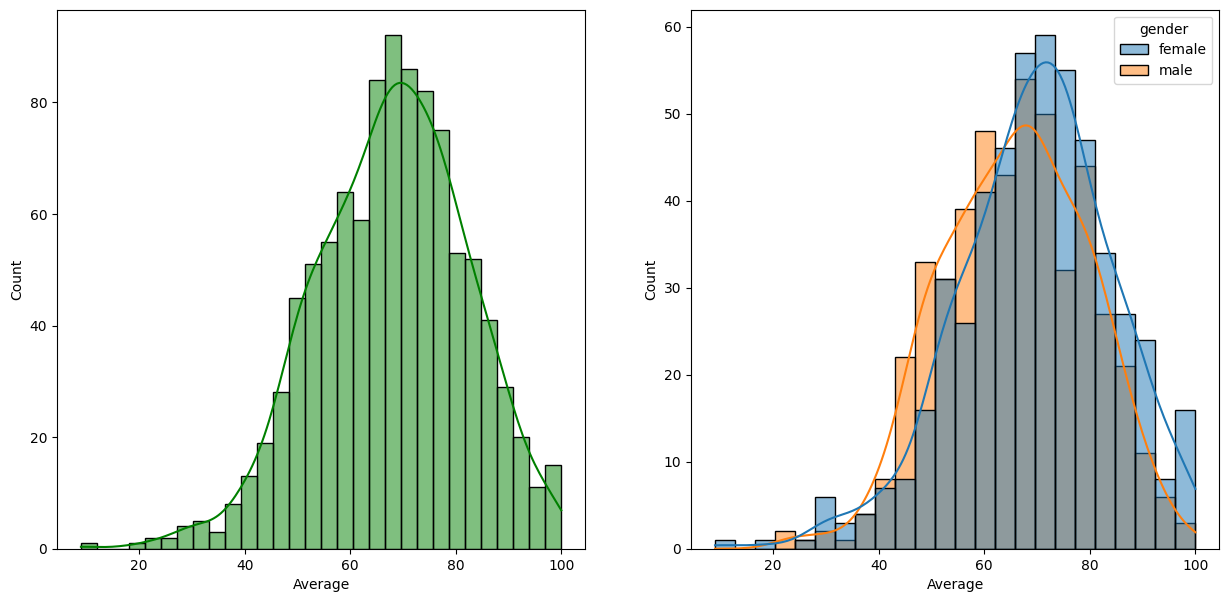

In [15]:
fig,axs = plt.subplots(1,2,figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='Average',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='Average',kde=True,hue='gender')
plt.show()

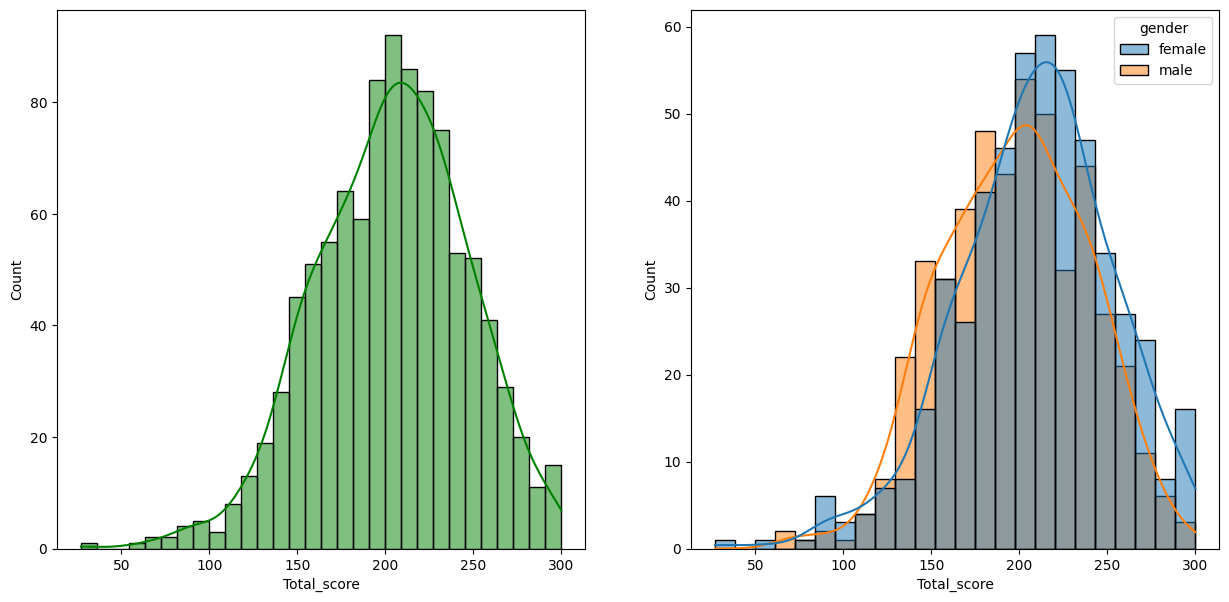

In [16]:
fig,axs = plt.subplots(1,2,figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='Total_score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='Total_score',kde=True,hue='gender')
plt.show()

Insights  
    • Female students perform well than male students


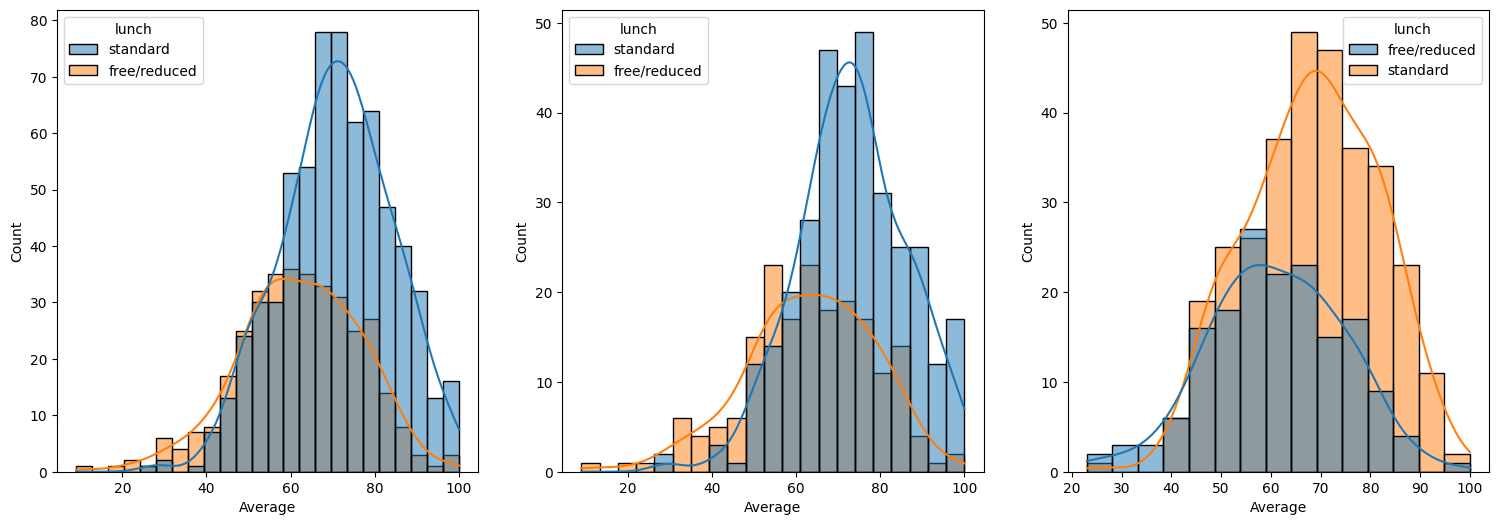

In [17]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
sns.histplot(data=df,x='Average',kde=True,hue='lunch')
plt.subplot(142)
sns.histplot(data=df[df.gender=='female'],x='Average',kde=True,hue='lunch')
plt.subplot(143)
sns.histplot(data=df[df.gender=='male'],x='Average',kde=True,hue='lunch')
plt.show()

Insights  
    • Standard lunch helps perform well in exams either its a male or female

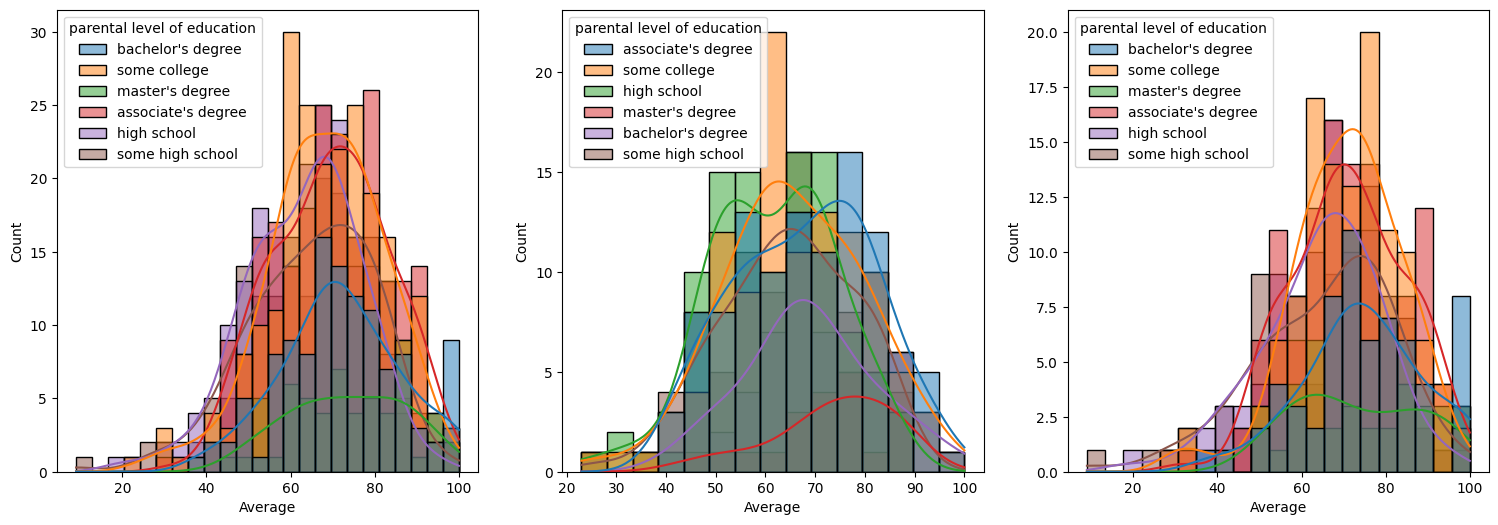

In [18]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
sns.histplot(data=df,x='Average',kde=True,hue='parental level of education')
plt.subplot(142)
sns.histplot(data=df[df.gender=='male'],x='Average',kde=True,hue='parental level of education')
plt.subplot(143)
sns.histplot(data=df[df.gender=='female'],x='Average',kde=True,hue='parental level of education')
plt.show()

Insights  
    • In general parents education don't helps students well in exams  
    • 2nd plot shows that parent's whose education is associate's degree or mastre's degree thair male children perform well in the exams  
    • 3rd plot we can see there is no effect of parent's education on female students


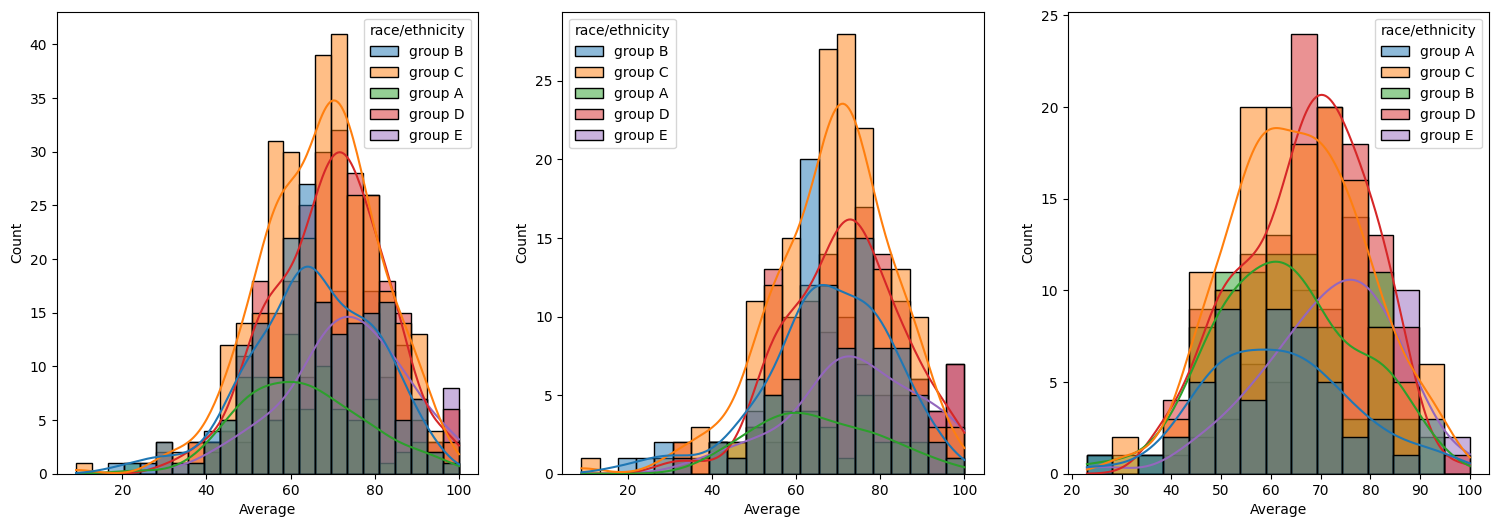

In [19]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
sns.histplot(data=df,x='Average',kde=True,hue='race/ethnicity')
plt.subplot(142)
sns.histplot(data=df[df.gender=='female'],x='Average',kde=True,hue='race/ethnicity')
plt.subplot(143)
sns.histplot(data=df[df.gender=='male'],x='Average',kde=True,hue='race/ethnicity')
plt.show()

Insights  
    • studets of group A and group B tends to perform poorly in exams  
    • studets of group A and group B tends to perform poorly in exams irrespective of whether they are male or female


# Maximum scores of students in all three subjects

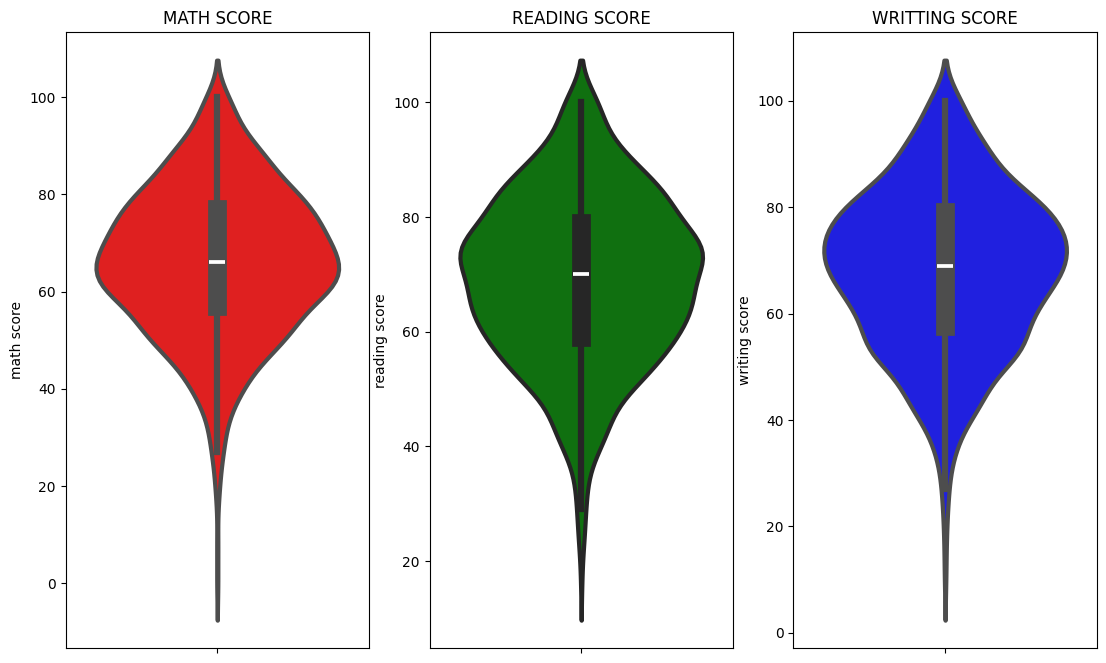

In [20]:
plt.figure(figsize=(18,8))
plt.subplot(1,4,1)
plt.title('MATH SCORE')
sns.violinplot(data=df,y='math score',color='red',linewidth=3)

plt.subplot(1,4,2)
plt.title('READING SCORE')
sns.violinplot(data=df,y='reading score',color='green',linewidth=3)

plt.subplot(1,4,3)
plt.title('WRITTING SCORE')
sns.violinplot(data=df,y='writing score',color='blue',linewidth=3)

plt.show()


Insights  
    • From the above three plots its clearly visible that most of the students score in between 60-80 in maths whereas in reading and writting most of them score from 50-80

# Multivariate Analysis using Pie PLot

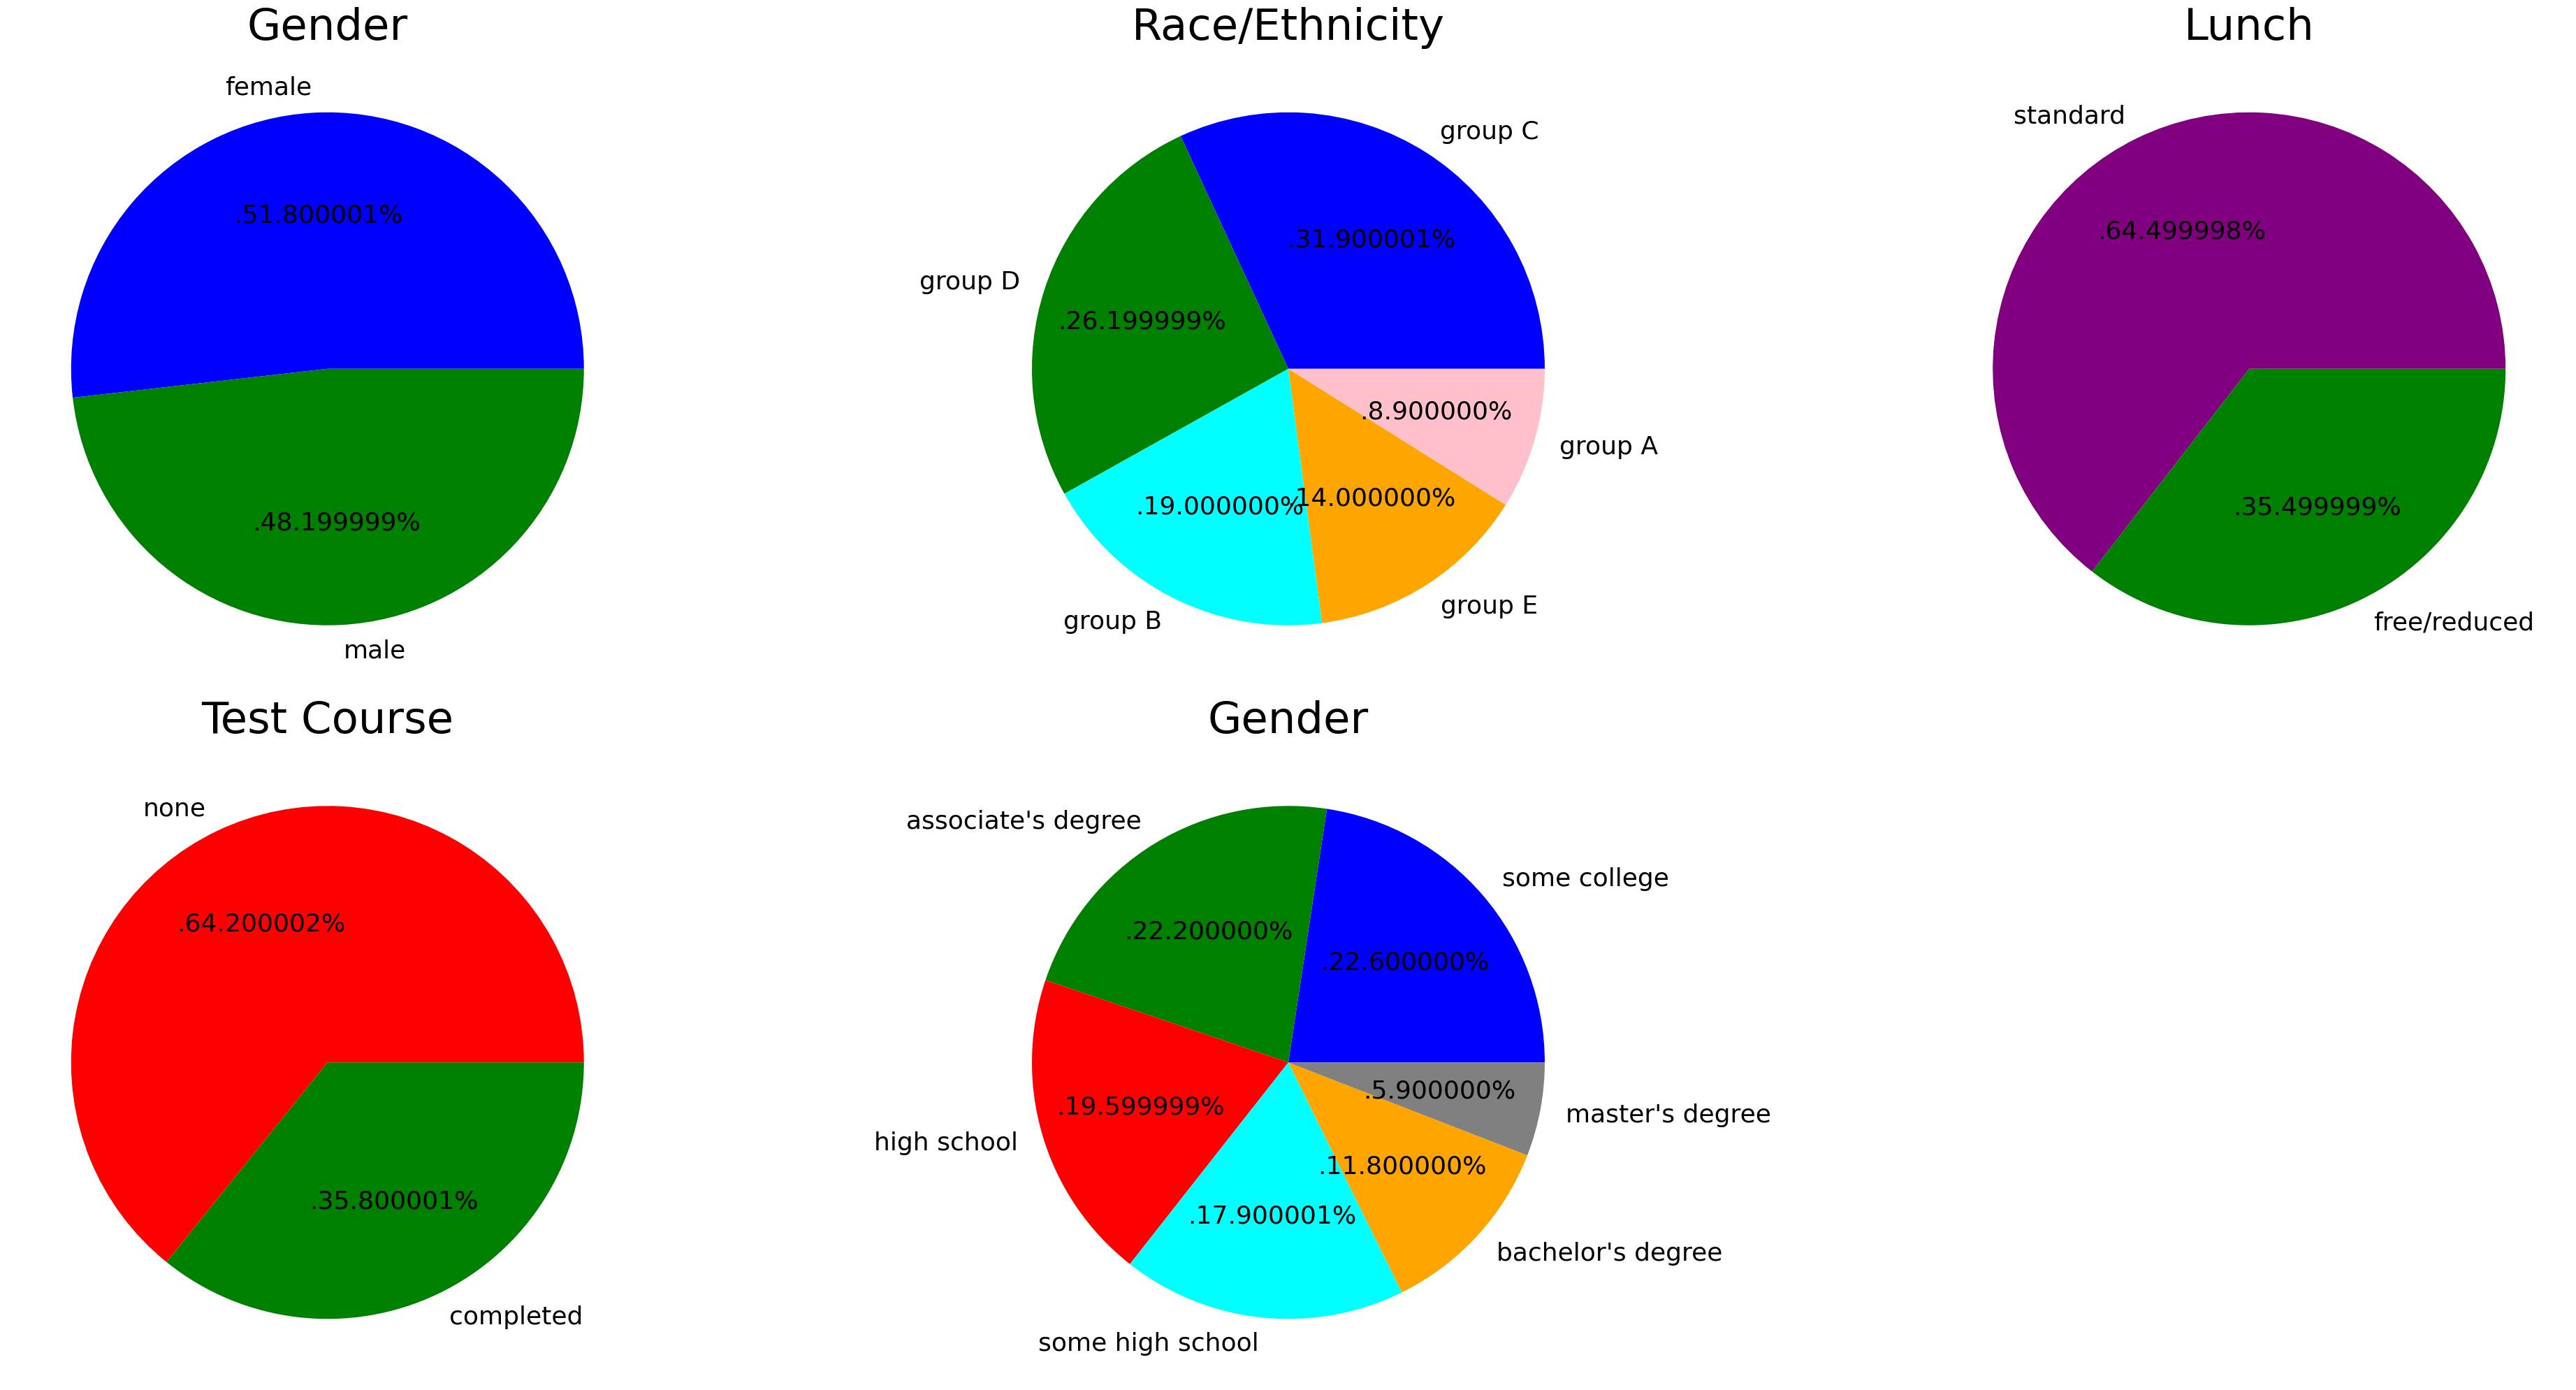

In [21]:
plt.rcParams['figure.figsize']=(40,20)

plt.subplot(2,3,1)
size=df['gender'].value_counts()
labels=size.index
color=['blue','green']


plt.pie(size,colors=color,labels=labels,autopct='.%2f%%',textprops={'fontsize':26})
plt.title('Gender',fontsize=45)
plt.axis('off')



plt.subplot(2,3,2)
size=df['race/ethnicity'].value_counts()
labels=size.index
color=['blue','green','cyan','orange','pink']


plt.pie(size,colors=color,labels=labels,autopct='.%2f%%',textprops={'fontsize':26})
plt.title('Race/Ethnicity',fontsize=45)
plt.axis('off')


plt.subplot(2,3,3)
size=df['lunch'].value_counts()
labels=size.index
color=['purple','green']


plt.pie(size,colors=color,labels=labels,autopct='.%2f%%',textprops={'fontsize':26})
plt.title('Lunch',fontsize=45)
plt.axis('off')


plt.subplot(2,3,4)
size=df['test preparation course'].value_counts()
labels=size.index
color=['red','green']


plt.pie(size,colors=color,labels=labels,autopct='.%2f%%',textprops={'fontsize':26})
plt.title('Test Course',fontsize=45)
plt.axis('off')

plt.subplot(2,3,5)
size=df['parental level of education'].value_counts()
labels=size.index
color=['blue','green','red','cyan','orange','grey']


plt.pie(size,colors=color,labels=labels,autopct='.%2f%%',textprops={'fontsize':26})
plt.title('Gender',fontsize=45)
plt.axis('off')

plt.tight_layout()
plt.grid()
plt.show()






Insights  
    • Number of Male and Female students are almost equal  
    • Number of students are greatest in Group C  
    • Number of students who have standard lunch are greater  
    • Number of students who have not enrolled in any test preparation course is greater  
    • Number of students whose parental education is "Some college" is greater followed by "Associate's degree"



# Feature wise visualization

Gender column

 # Univariate Analysis (How is distribution of gender)

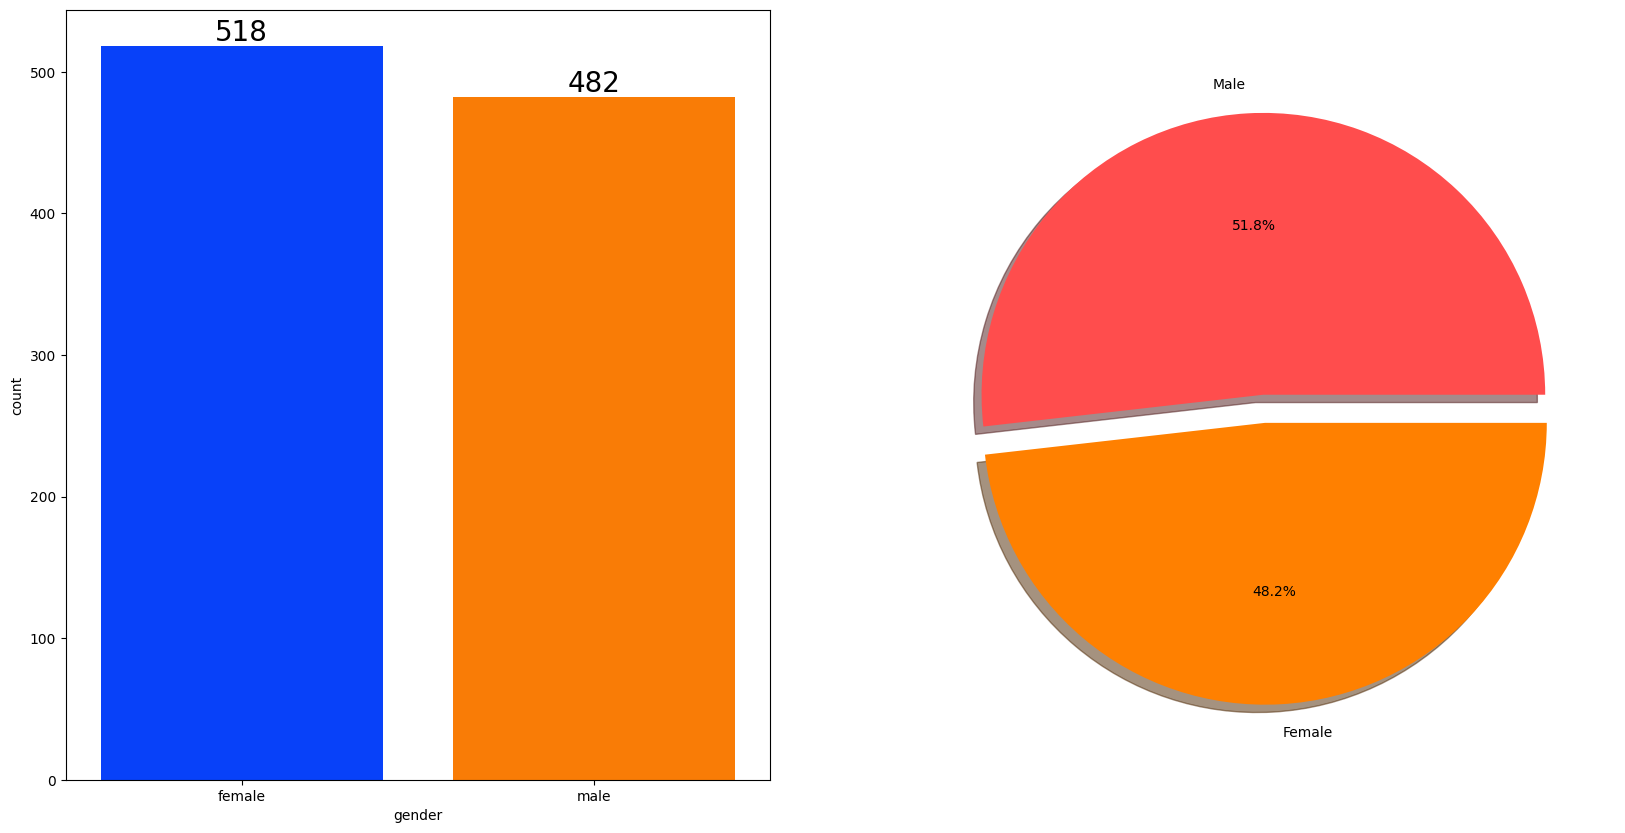

In [22]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(data=df,x=df['gender'],palette='bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)

plt.pie(x=df['gender'].value_counts(),labels=['Male','Female'],explode=[0,0.1],autopct='%1.1f%%',shadow=True,colors=['#ff4d4d','#ff8000'])
plt.show()

Insights  
    • Gender has balanced data with female  students are 518(48 %) and male students are 482(52 %)



# Bivariate Analysis (Is gender has any impact on student performance?)

In [23]:
gender_group=df.groupby('gender').mean(numeric_only=True)
gender_group

,math score,reading score,writing score,Total_score,Average
gender,,,,,
female,63.633205,72.608108,72.467181,208.708494,69.569498
male,68.728216,65.473029,63.311203,197.512448,65.837483


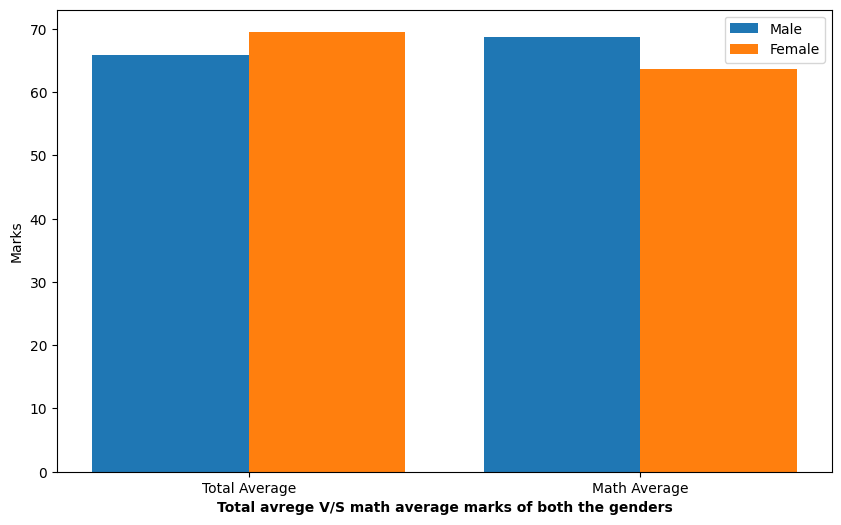

In [24]:
plt.figure(figsize=(10,6))
X = ['Total Average','Math Average']

female_scores=[gender_group['Average'][0],gender_group['math score'][0]]
male_scores=[gender_group['Average'][1],gender_group['math score'][1]]

X_axis=np.arange(len(X))

plt.bar(X_axis-0.2,male_scores,0.4,label='Male')
plt.bar(X_axis+0.2,female_scores,0.4,label='Female')

plt.xticks(X_axis,X)
plt.ylabel('Marks')
plt.xlabel('Total avrege V/S math average marks of both the genders',fontweight='bold')
plt.legend()
plt.show()

 # race/ethnicity column

 # Univariate Analysis (How is Group wise distribution)

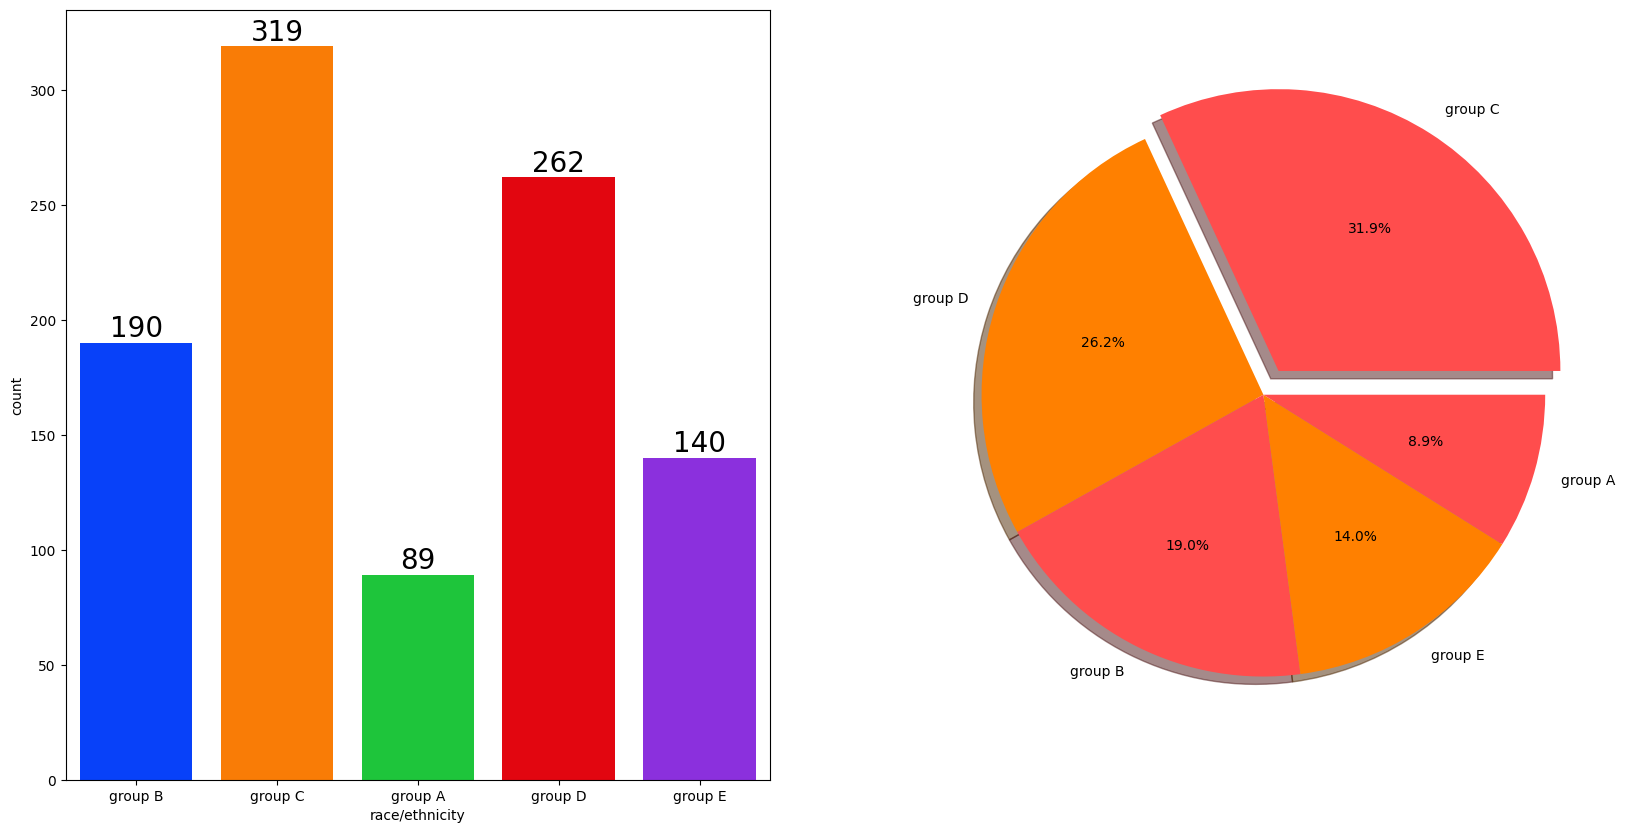

In [25]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(data=df,x=df['race/ethnicity'],palette='bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)

plt.pie(x=df['race/ethnicity'].value_counts(),labels=df['race/ethnicity'].value_counts().index,explode=[0.1,0,0,0,0],autopct='%1.1f%%',shadow=True,colors=['#ff4d4d','#ff8000'])
plt.show()

Insights  
    • Most of the students belongig from group C / group D  
    • Lowest number of students belongingn to group A


# Bivariate Analysis (Is race/ethnicity has any impact on student performance?)

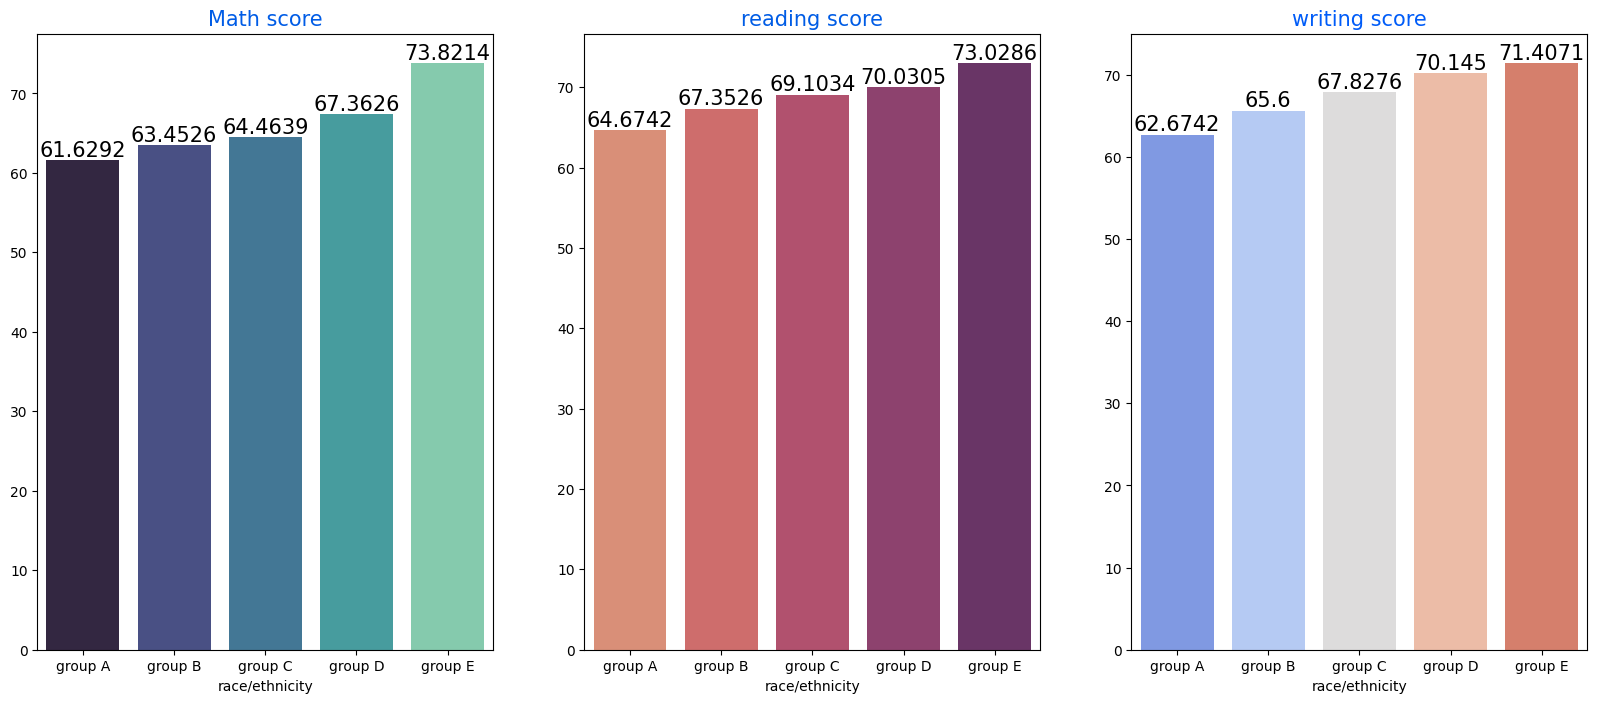

In [26]:
Group_data2=df.groupby('race/ethnicity')
f,ax=plt.subplots(1,3,figsize=(20,8))
sns.barplot(x=Group_data2['math score'].mean().index,y=Group_data2['math score'].mean().values,palette='mako',ax=ax[0])
ax[0].set_title('Math score',color='#005ce6',size=15)

for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=15)



sns.barplot(x=Group_data2['reading score'].mean().index,y=Group_data2['reading score'].mean().values,palette='flare',ax=ax[1])
ax[1].set_title('reading score',color='#005ce5',size=15)

for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=15)


sns.barplot(x=Group_data2['writing score'].mean().index,y=Group_data2['writing score'].mean().values,palette='coolwarm',ax=ax[2])
ax[2].set_title('writing score',color='#005cf8',size=15)

for container in ax[2].containers:
    ax[2].bar_label(container,color='black',size=15)




Insights  
    • Group E students have scored the highest marks  
    • Group A students have scored the lowest marks  


# Parental Level of Education

 # Univariate Analysis (What is the educatioanal background of student's parents)

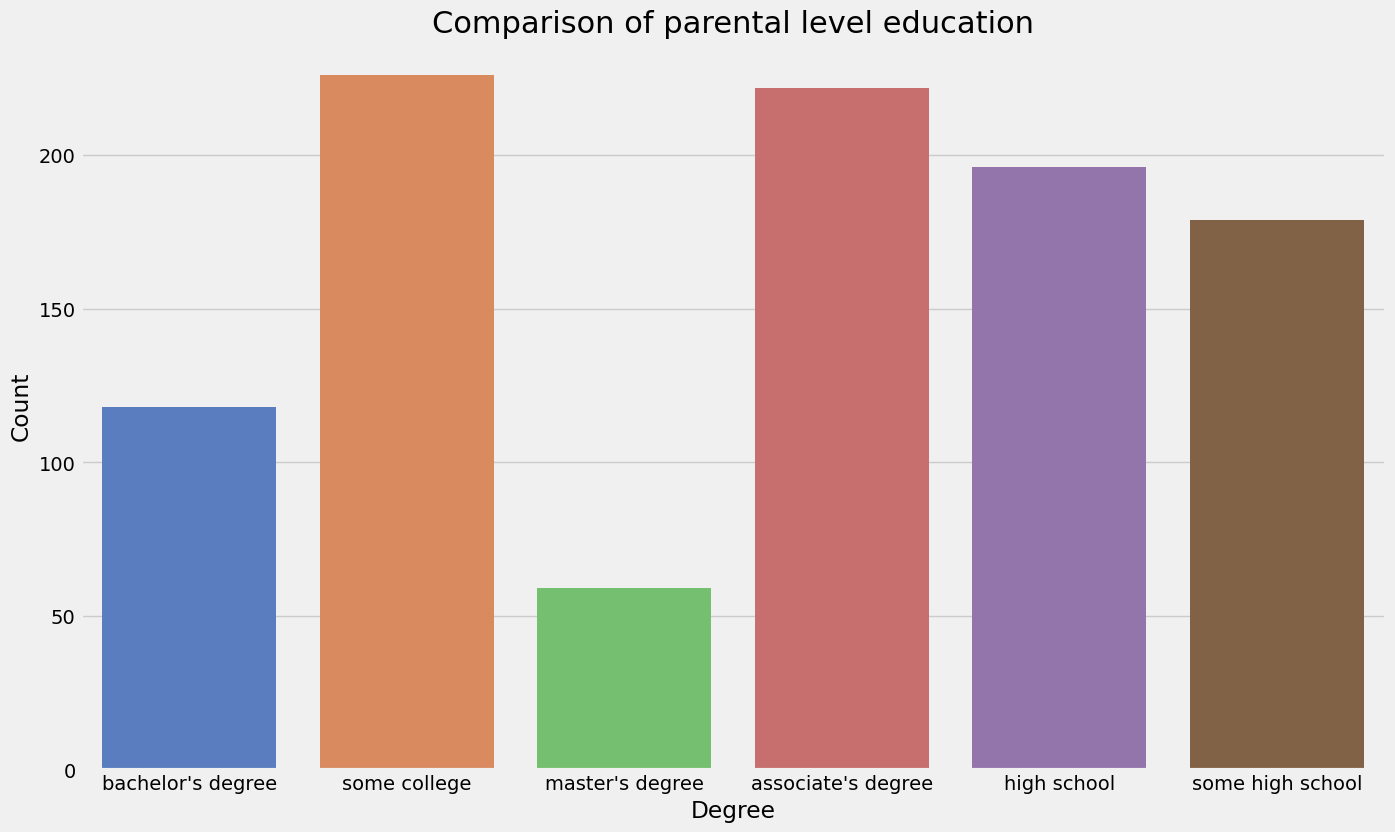

In [27]:
plt.rcParams['figure.figsize']=(15,9)
plt.style.use('fivethirtyeight')

sns.countplot(data=df,x=df['parental level of education'],palette='muted')

plt.title('Comparison of parental level education',fontweight=30,fontsize=22)
plt.xlabel('Degree')
plt.ylabel('Count')
plt.show()

Insights  
    • Largest number of parents are from either 'some college' or 'associate's degree

# Bivariate Analysis (Is parental level of education  has any impact on student performance?)

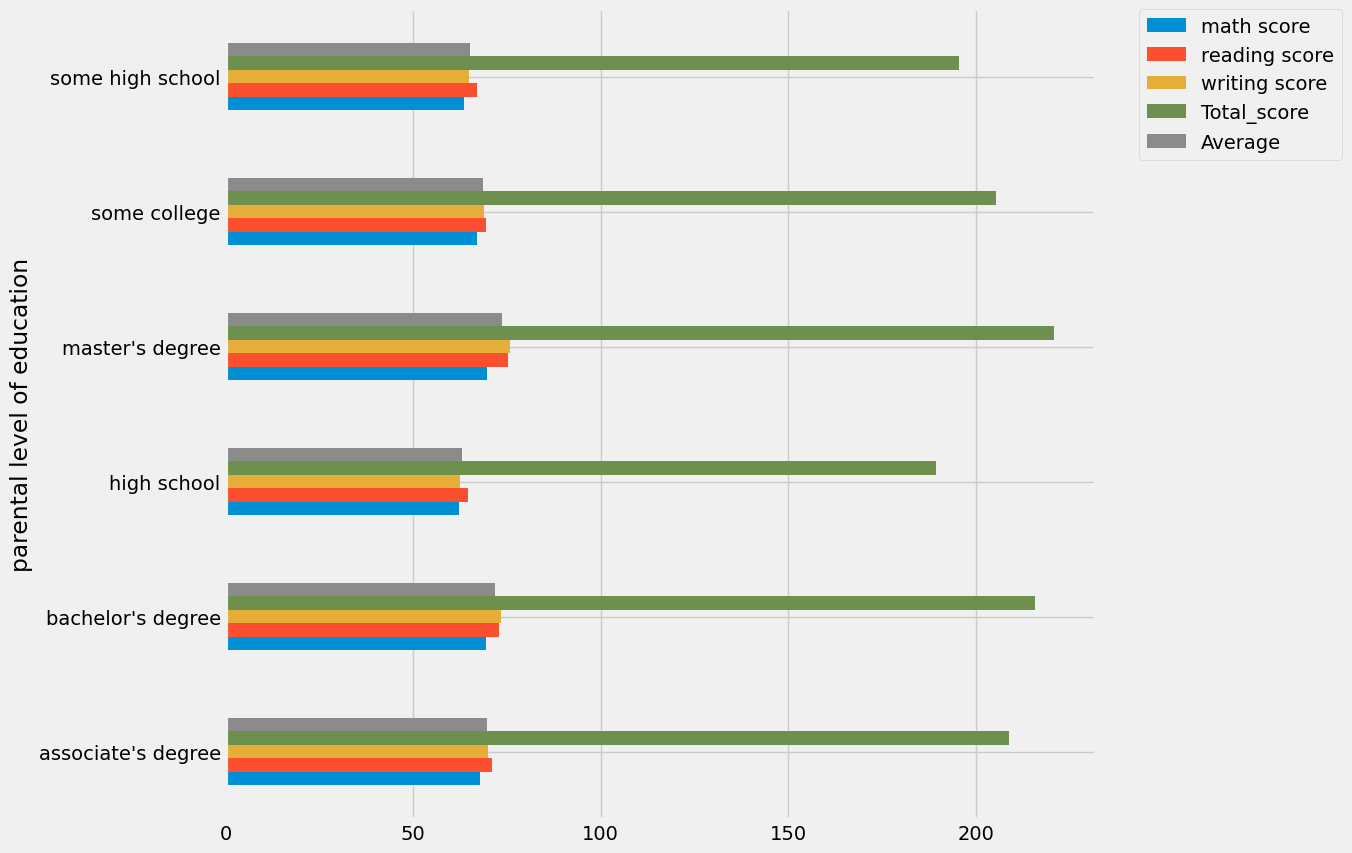

In [28]:
df.groupby('parental level of education').mean(numeric_only=True).plot(kind='barh',figsize=(10,10))
plt.legend(bbox_to_anchor=(1.05,1),loc=2,borderaxespad=0.)

plt.show()

Insights  
    • The score of students whose parents possess master and bachelor level education are higher than others


# Lunch column

 # Univariate Analysis (Which type of lunch is most common among studets)

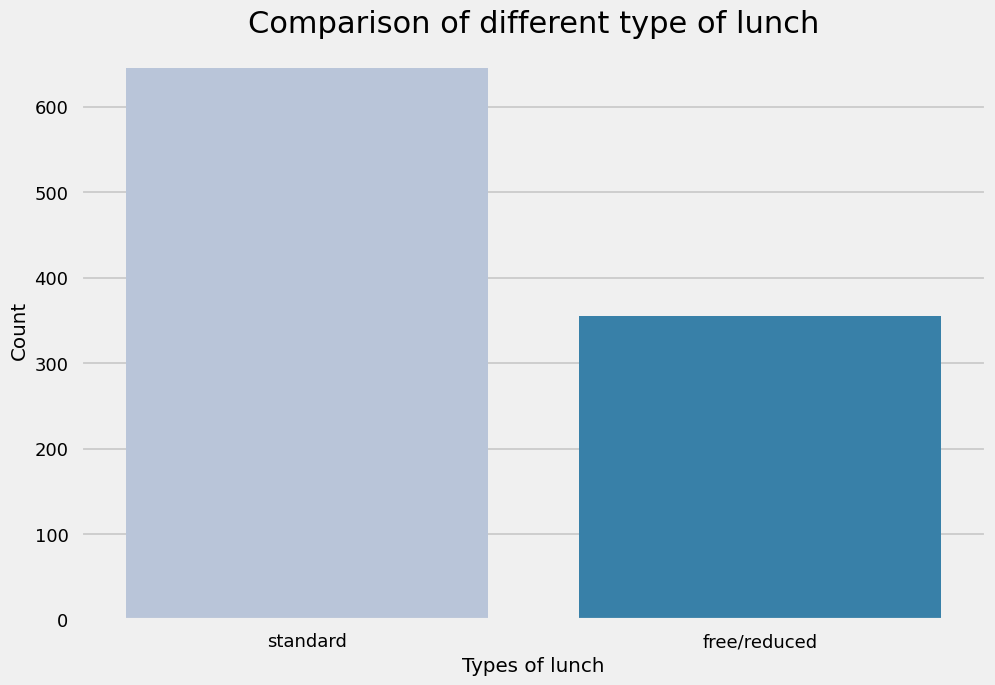

In [29]:
plt.rcParams['figure.figsize']=(15,9)
plt.style.use('seaborn-talk')

sns.countplot(data=df,x=df['lunch'],palette='PuBu')

plt.title('Comparison of different type of lunch',fontweight=30,fontsize=22)
plt.xlabel('Types of lunch')
plt.ylabel('Count')
plt.show()

Insights  
    • Students bieng served Standard lunch was more than free lunch


# Bivariate Analysis (Is lunch has any impact on student performance?)

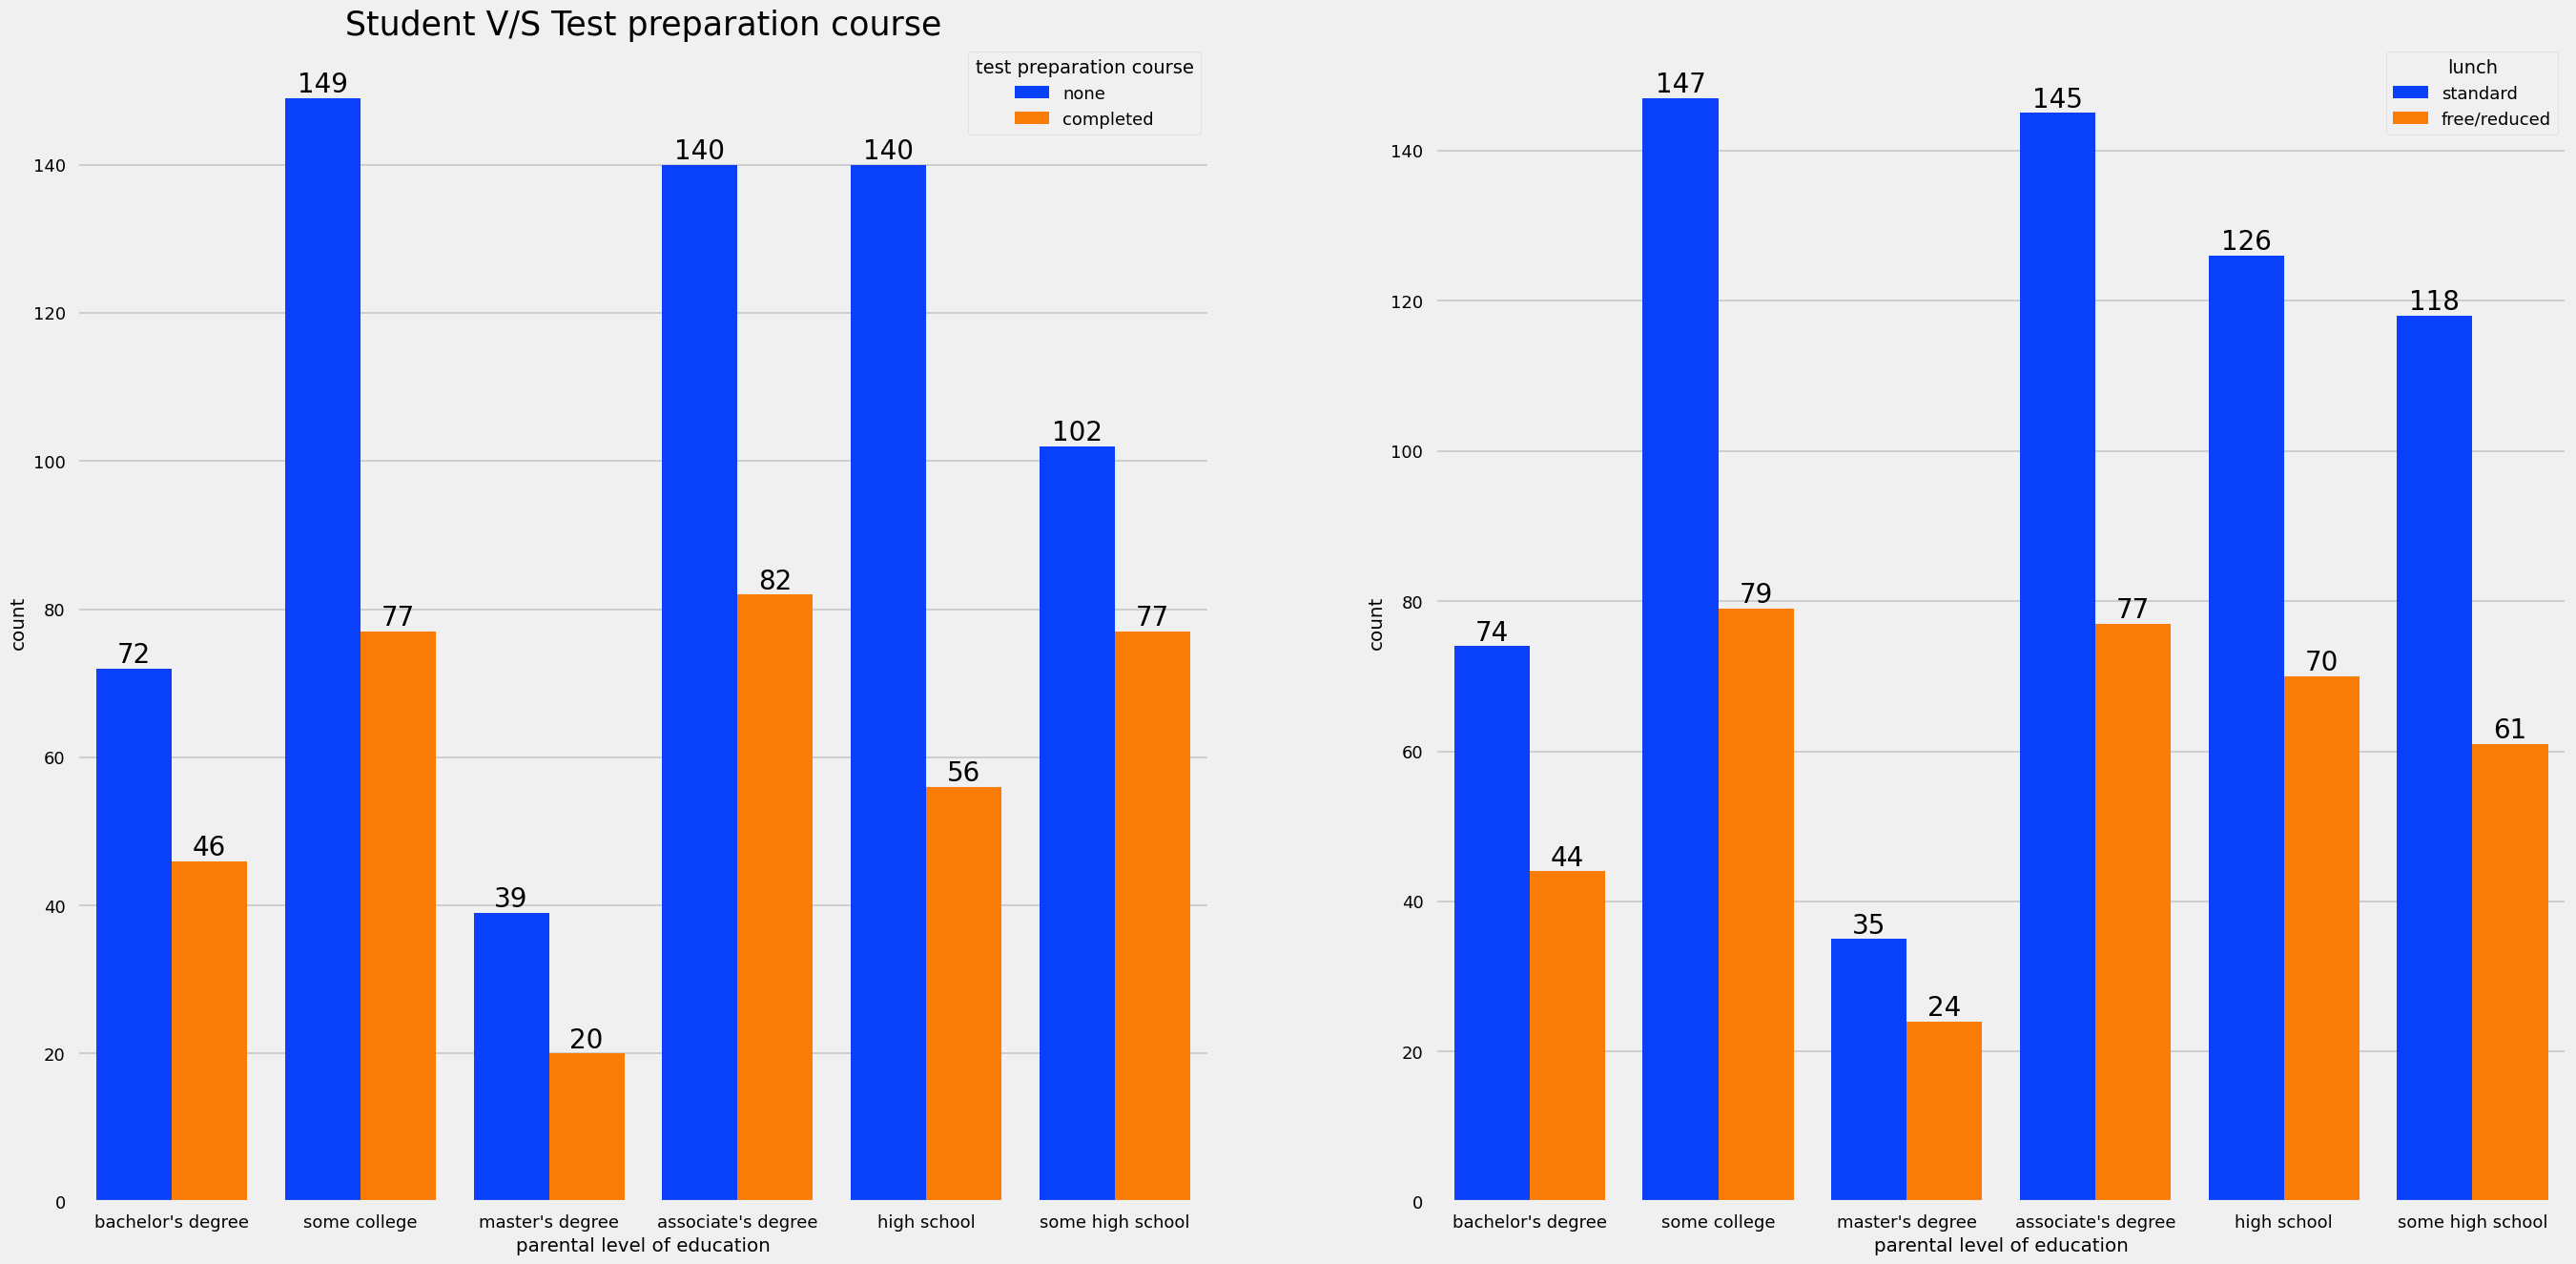

In [30]:
f,ax=plt.subplots(1,2,figsize=(30,15))
sns.countplot(data=df,x=df['parental level of education'],palette='bright',hue='test preparation course',ax=ax[0],saturation=0.95)
ax[0].set_title('Student V/S Test preparation course',color='black',size=25)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)

sns.countplot(data=df,x=df['parental level of education'],palette='bright',hue='lunch',saturation=0.95,ax=ax[1])
for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=20)

Insights  
    • Students who get standard lunch tend to perform better than students who get free/reduced lunch


# Test Preparation course column

# Bivariate Analysis (Is Test preparation course has any impact on student performance?)

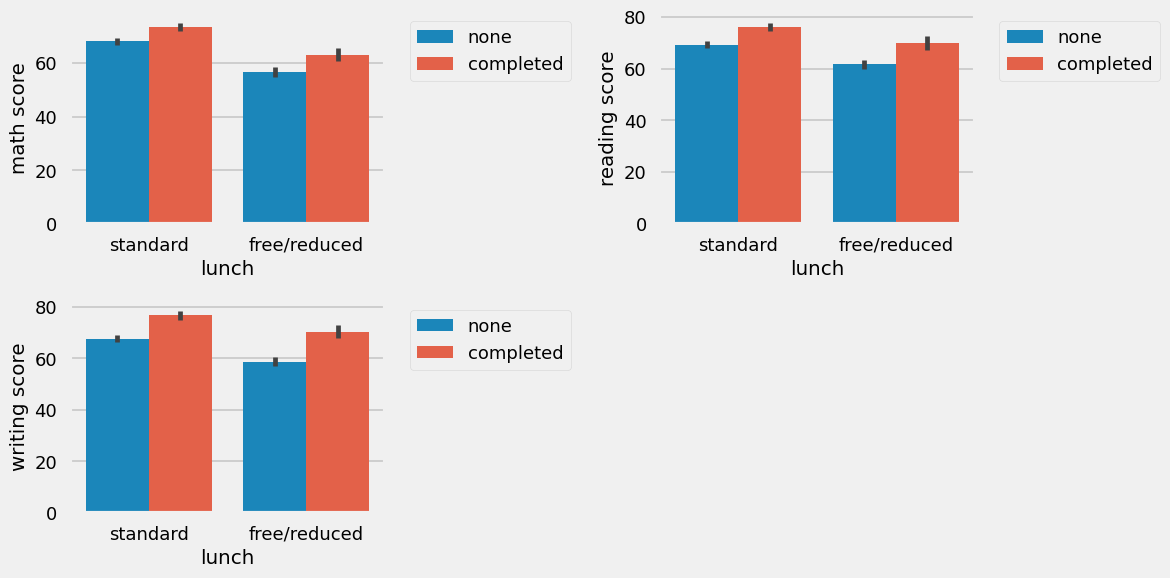

In [31]:
plt.figure(figsize=(12,6))
plt.subplot(2,2,1)
sns.barplot(x=df['lunch'],y=df['math score'],hue=df['test preparation course'])
plt.legend(bbox_to_anchor=(1.05,1),loc='upper left')

plt.subplot(2,2,2)
sns.barplot(x=df['lunch'],y=df['reading score'],hue=df['test preparation course'])
plt.legend(bbox_to_anchor=(1.05,1),loc='upper left')

plt.subplot(2,2,3)
sns.barplot(x=df['lunch'],y=df['writing score'],hue=df['test preparation course'])

plt.legend(bbox_to_anchor=(1.05,1),loc='upper left')
plt.tight_layout()
plt.show()

Insights  
    • Students who have completed the Test preparetion course have scores higher in all three categories than who haven't taken the course


# Checking outliers

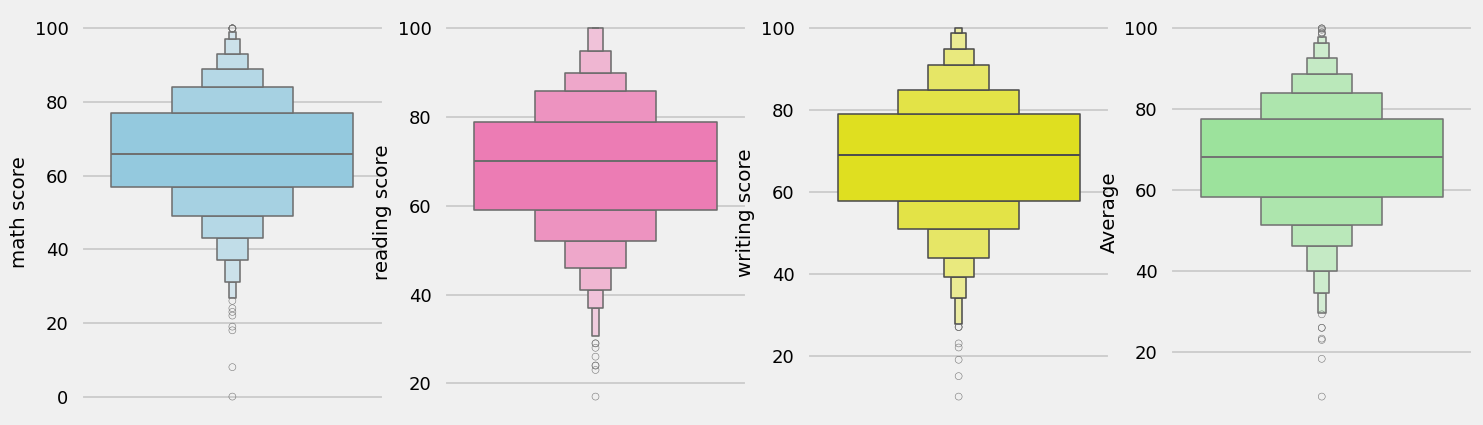

In [32]:
plt.subplots(1,4,figsize=(16,5))
plt.subplot(141)
sns.boxenplot(df['math score'],color='skyblue')

plt.subplot(142)
sns.boxenplot(df['reading score'],color='hotpink')

plt.subplot(143)
sns.boxenplot(df['writing score'],color='yellow')

plt.subplot(144)
sns.boxenplot(df['Average'],color='lightgreen')

plt.show()

# Multi variate analysis using pairplot

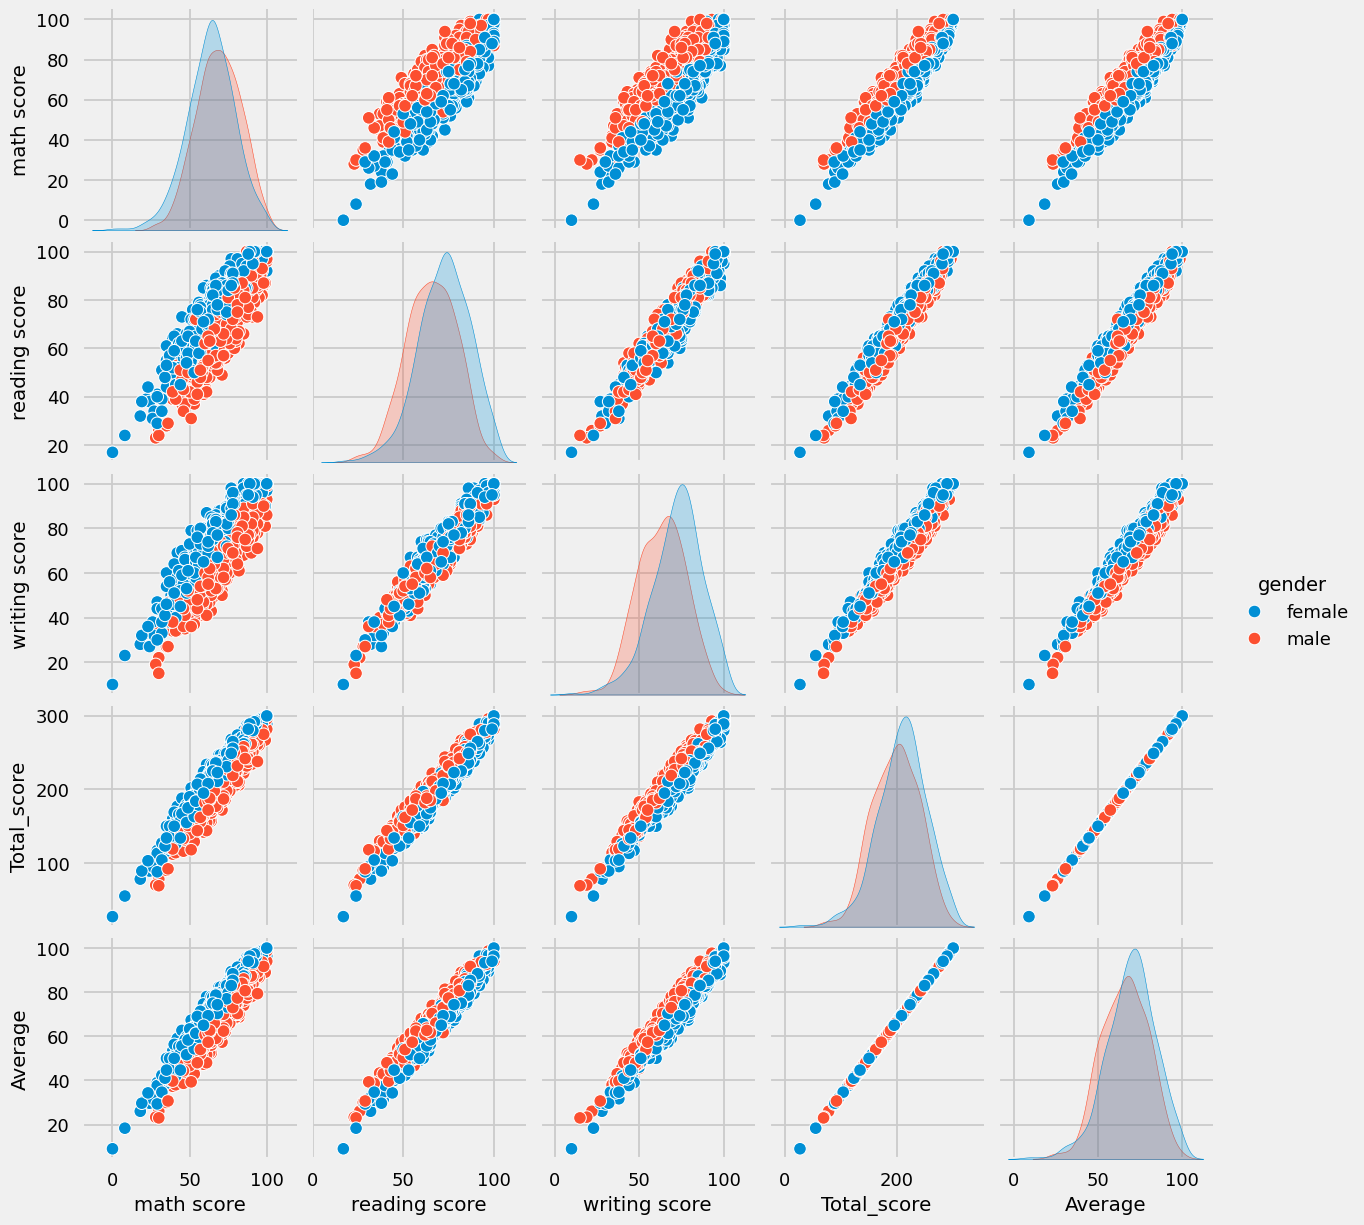

In [33]:
sns.pairplot(df,hue='gender')
plt.show()

Insights  
    • From the above plot it is clear that all the scores increase linearly with each other

# Conclusions
    • Student's performance is related with lunch,race,parental level education  
    • female's lead in pass percentage and also are top scores   
    • Student's performance is not much related with test preparation course  
    • finishing preparation course is benefitial  

